## Week 1 · Exploratory Data Analysis (EDA)  🔎

Before training any model, it is good practice to **look at the data first**. Exploratory Data Analysis (EDA) is the step of summarising and visualising a dataset to understand its main characteristics: how much data there is, how it is distributed, and whether it hides problems such as class imbalance, outliers, mislabelled samples or inconsistent recording conditions.

With EDA, you will be able to make *informed* decisions that come next: how to clean the data, which augmentations make sense, and what performance to expect. The better you know your data, the fewer surprises during training.

Ensure your dataset has one folder per sequence, each with an `images/` and a `labels/` subfolder:

```
dataset/
└── Video_1/
    ├── images/   # frames (.jpg)
    └── labels/   # bounding boxes (.xml, Pascal VOC)
```

### Imports

In [1]:
import os
import itertools
import numpy as np
import pandas as pd
from tqdm import tqdm
from PIL import Image
from scipy import ndimage
import xml.etree.ElementTree as ET

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

### Load the dataset

Point `PATH_DATA` to your dataset, then load every label into a nested dictionary `DATA[sequence][frame] = {'frame_path', 'size', 'bboxes'}`.

In [2]:
PATH_DATA = '../data_train'

In [3]:
def list_dir(path):
    """List a folder, skipping caches like __pycache__ and .ipynb_checkpoints."""
    return sorted(e for e in os.listdir(path) if not e.startswith('.') and e != '__pycache__')


def load_labels(xml_path):
    """Read a Pascal VOC .xml file, returning (frame_filename, (width, height), list of [x_min, y_min, x_max, y_max])."""
    root = ET.parse(xml_path).getroot()
    frame_filename = root.find('filename').text
    size = root.find('size')
    img_size = (int(size.find('width').text), int(size.find('height').text))
    bboxes = [[int(box.find(c).text) for c in ('xmin', 'ymin', 'xmax', 'ymax')]
              for box in root.iter('bndbox')]
    return frame_filename, img_size, bboxes


def load_data(path, sequences):
    """Load every sequence into data[sequence][frame] = {'frame_path', 'size', 'bboxes'}."""
    data = {}
    for seq in sequences:
        data[seq] = {}
        labels_dir = os.path.join(path, seq, 'labels')
        for label_file in list_dir(labels_dir):
            frame_filename, img_size, bboxes = load_labels(os.path.join(labels_dir, label_file))
            frame_path = os.path.join(path, seq, 'images', frame_filename)
            frame_name = os.path.splitext(label_file)[0]
            data[seq][frame_name] = {'frame_path': frame_path, 'size': img_size, 'bboxes': bboxes}
    return data

In [4]:
# Every subfolder of PATH_DATA is a sequence (skipping the '-aug' copies made by data_aug.ipynb)
SEQUENCES = [s for s in list_dir(PATH_DATA)
             if os.path.isdir(os.path.join(PATH_DATA, s)) and not s.endswith('-aug')]
DATA = load_data(PATH_DATA, SEQUENCES)
print(f'Loaded {len(SEQUENCES)} sequences: {SEQUENCES}')

Loaded 12 sequences: ['RoboMaster-Fuera1', 'RoboMaster-Fuera2', 'RoboMaster-Hall1', 'RoboMaster-Hall2', 'RoboMaster-Hall3', 'RoboMaster-Hall4', 'RoboMaster-Pasillo', 'RoboMaster-Sala1', 'RoboMaster-Sala2', 'RoboMaster-Sala3', 'RoboMaster-Sala4', 'RoboMaster-Sala5']


### Show a frame

Each box is drawn as a coloured outline so it stands out without hiding the pixels underneath.

In [5]:
def show_frame(element, color='tab:green'):
    """Display a frame with its bounding boxes drawn on top."""
    ax = plt.gca()
    ax.imshow(plt.imread(element['frame_path']))
    ax.axis('off')
    for x_min, y_min, x_max, y_max in element['bboxes']:
        # Coloured outline, no fill
        ax.add_patch(Rectangle((x_min, y_min), x_max - x_min, y_max - y_min,
                               linewidth=2, edgecolor=color, facecolor='none'))
    plt.show()

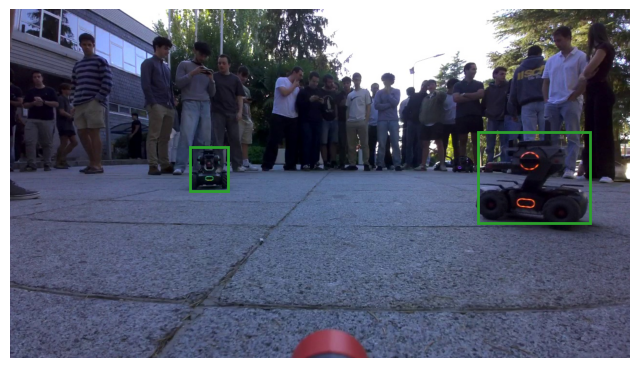

In [6]:
# Pick any frame (here, the first one of the first sequence)
sequence = SEQUENCES[0]
frame_name = list(DATA[sequence])[0]
plt.figure(figsize=(8, 5))
show_frame(DATA[sequence][frame_name])

### Frames and boxes per sequence

In [7]:
def bar_plot(counts, title, ylabel, color='tab:blue'):
    """Draw a bar chart from a {name: count} dict, widening with the number of bars."""
    plt.figure(figsize=(max(6, 1.2 * len(counts)), 4))
    bars = plt.bar(list(counts), list(counts.values()), color=color)
    # Labels inside the bars, in white, to avoid colliding with the title
    plt.bar_label(bars, label_type='center', color='white', fontweight='bold')
    plt.title(title)
    plt.ylabel(ylabel)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()


def plot_frames_per_sequence(data):
    """Bar chart of the number of frames per sequence."""
    counts = {seq: len(frames) for seq, frames in data.items()}
    bar_plot(counts, 'Frames per sequence', 'Number of frames')


def plot_boxes_per_sequence(data):
    """Bar chart of the number of bounding boxes per sequence."""
    counts = {seq: sum(len(f['bboxes']) for f in frames.values()) for seq, frames in data.items()}
    bar_plot(counts, 'Bounding boxes per sequence', 'Number of boxes')


def subplot_grid(n, sharey=True):
    """Create a grid of n subplots (max 4 per row) and return (fig, flat axes for the n plots)."""
    ncols = min(n, 4)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.5 * nrows), sharey=sharey, squeeze=False)
    axes = axes.ravel()
    for ax in axes[n:]:   # hide the empty cells of the last row
        ax.axis('off')
    return fig, axes[:n]

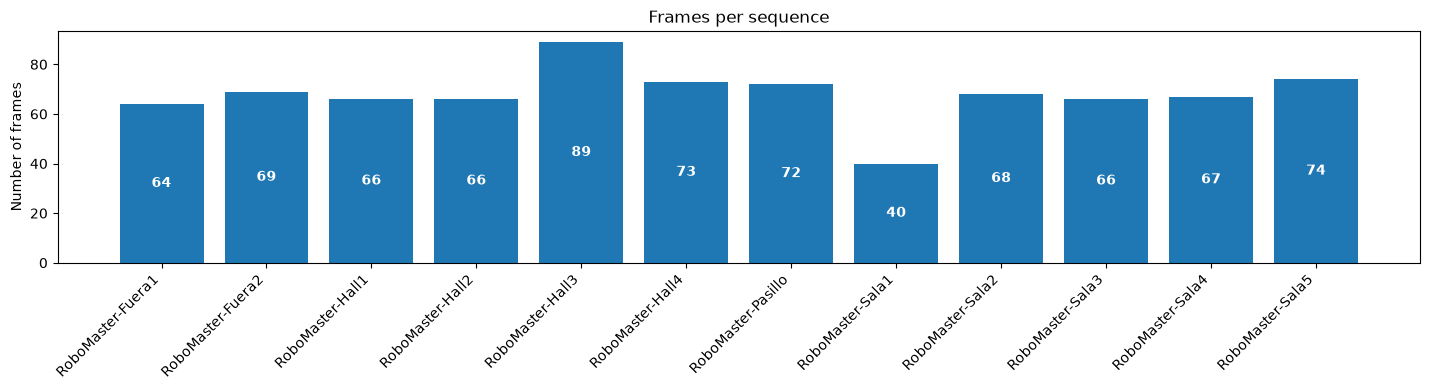

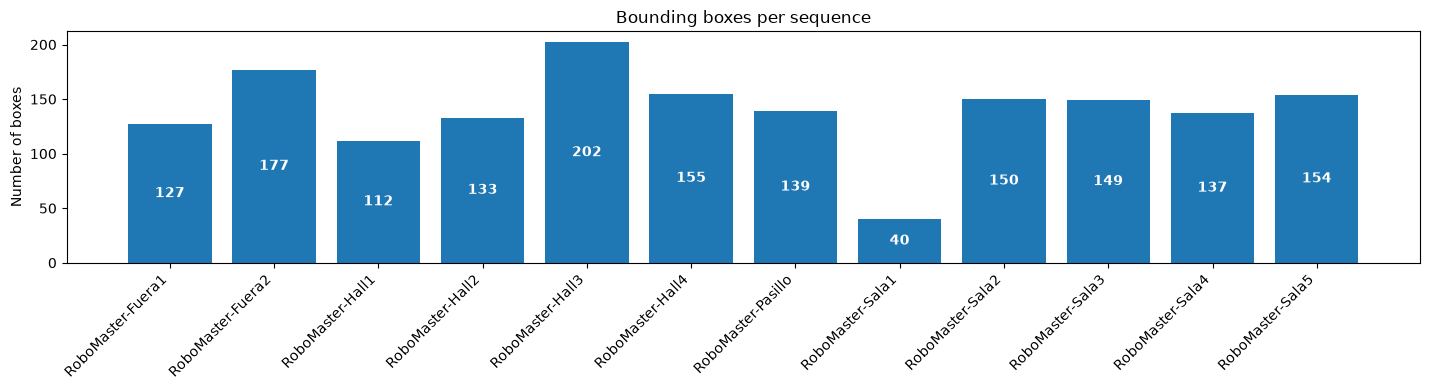

In [8]:
plot_frames_per_sequence(DATA)
plot_boxes_per_sequence(DATA)

---
## Bounding-box statistics

From here on every box is one row of a table. Coordinates are also **normalised** by the image size (0–1), so sequences recorded at different resolutions can be compared.

Sequences are grouped into **scenarios** by dropping the trailing number from their name (`RoboMaster-Hall3` → `Hall`).

In [9]:
def scenario(seq):
    """Scenario of a sequence: its name without the 'RoboMaster-' prefix and the trailing number."""
    return seq.replace('RoboMaster-', '').rstrip('0123456789')


def box_table(data):
    """One row per box with its sequence, scenario, size and position (in pixels and normalised)."""
    rows = []
    for seq, frames in data.items():
        for frame_name, f in frames.items():
            width, height = f['size']
            for x_min, y_min, x_max, y_max in f['bboxes']:
                w, h = x_max - x_min, y_max - y_min
                rows.append({'sequence': seq, 'scenario': scenario(seq), 'frame': frame_name,
                             'w': w, 'h': h, 'area': w * h, 'aspect': w / h if h else np.nan,
                             'w_norm': w / width, 'h_norm': h / height,
                             'cx_norm': (x_min + x_max) / 2 / width, 'cy_norm': (y_min + y_max) / 2 / height})
    return pd.DataFrame(rows)


BOXES = box_table(DATA)
SCENARIOS = sorted(BOXES['scenario'].unique())
BOXES.describe().round(2)

,w,h,area,aspect,w_norm,h_norm,cx_norm,cy_norm
count,1675.00,1675.00,1675.00,1675.00,1675.00,1675.00,1675.00,1675.00
mean,139.58,135.00,28481.11,1.08,0.11,0.19,0.50,0.47
std,99.53,103.49,54936.81,0.20,0.08,0.14,0.20,0.08
min,17.00,22.00,680.00,0.37,0.01,0.03,0.01,0.25
25%,76.00,70.00,5455.50,0.94,0.06,0.10,0.38,0.43
50%,111.00,101.00,11115.00,1.08,0.09,0.14,0.50,0.47
75%,170.00,158.00,26559.00,1.21,0.13,0.22,0.63,0.50
max,991.00,717.00,710547.00,2.05,0.77,1.00,0.98,0.90


### Robots per frame

How many robots appear in each frame. Frames with **0** robots are negatives: they teach the model what is *not* a robot, but too many of them make training slower.

In [10]:
def plot_boxes_per_frame(data):
    """Histogram of the number of boxes per frame, one subplot per sequence."""
    counts = {seq: [len(f['bboxes']) for f in frames.values()] for seq, frames in data.items()}
    bins = np.arange(max(max(c) for c in counts.values()) + 2) - 0.5   # one bar per integer
    fig, axes = subplot_grid(len(data))
    fig.suptitle('Robots per frame')
    for ax, (seq, c) in zip(axes, counts.items()):
        ax.hist(c, bins=bins, color='tab:blue', rwidth=0.8)
        ax.set_title(f'{seq}\n({np.mean(np.array(c) == 0):.0%} empty)')
        ax.set_xlabel('Robots in the frame')
        ax.set_xticks(range(len(bins) - 1))
    axes[0].set_ylabel('Frames')
    plt.tight_layout()
    plt.show()

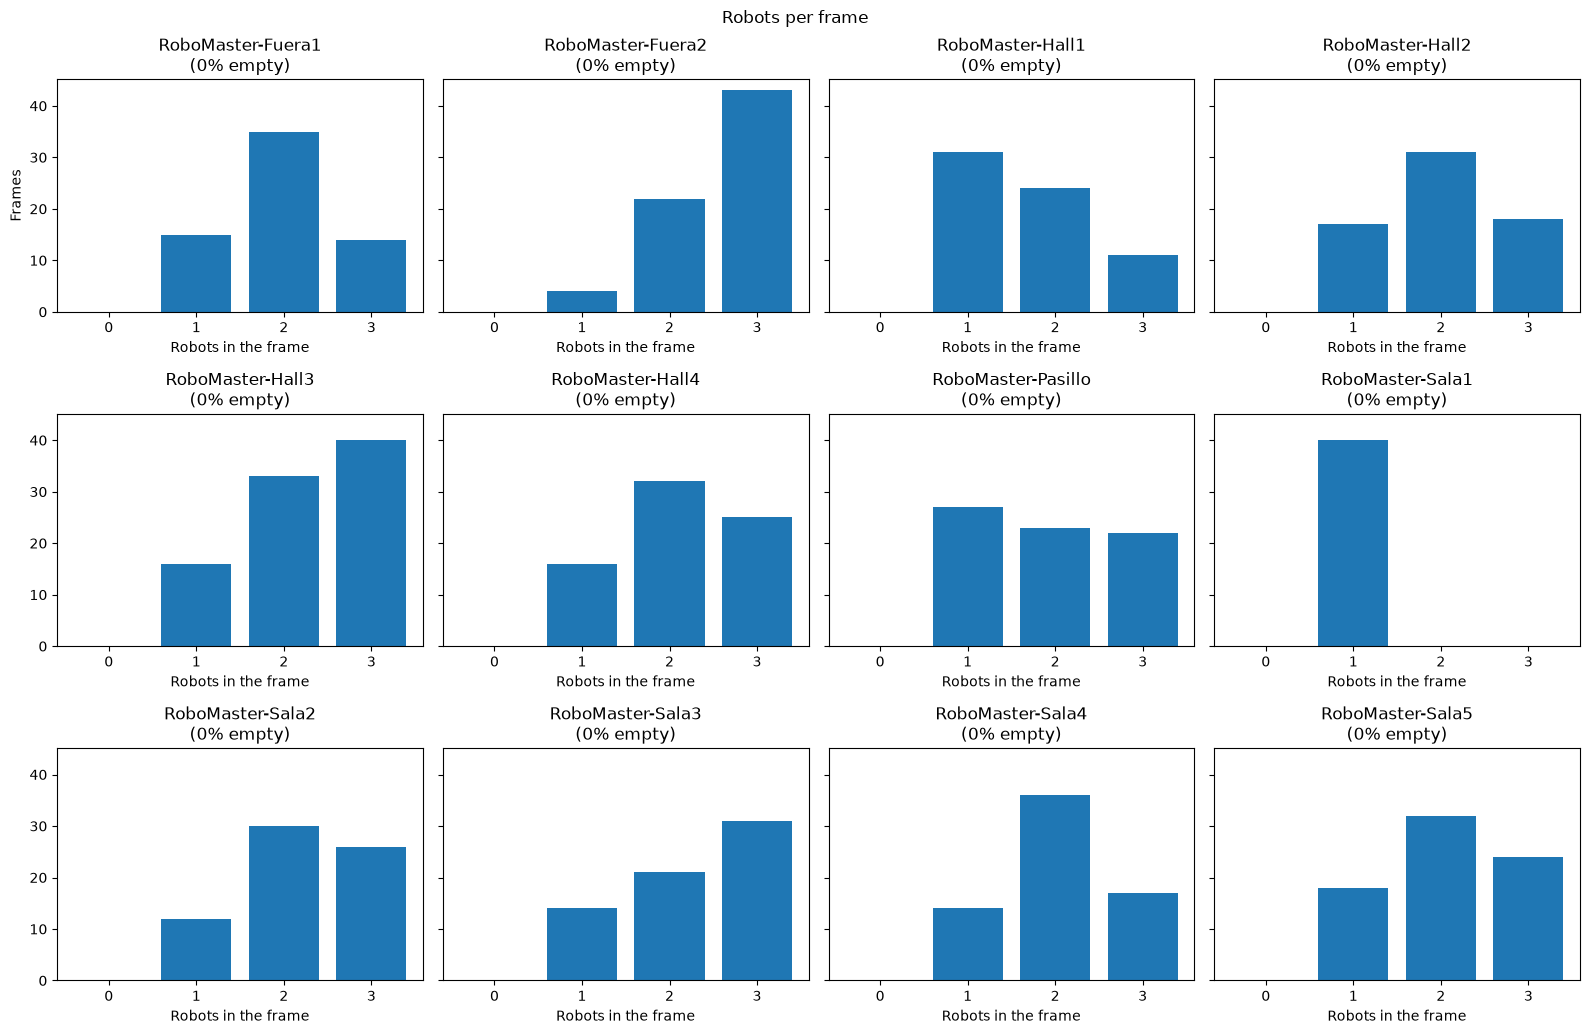

In [11]:
plot_boxes_per_frame(DATA)

### Images without a label

Frames that have an image but no `.xml`. They are not loaded, so the rest of the EDA ignores them. Look at them and decide:
- **No robot visible** → they are useful negatives: create an `.xml` with no objects so the model sees them.
- **Robots visible** → the annotation was forgotten: label them.

In [12]:
def unlabelled_frames(path, data):
    """Images on disk that have no .xml label, as a list of (sequence, image path)."""
    missing = []
    for seq, frames in data.items():
        labelled = {os.path.basename(f['frame_path']) for f in frames.values()}
        images_dir = os.path.join(path, seq, 'images')
        missing += [(seq, os.path.join(images_dir, img)) for img in list_dir(images_dir) if img not in labelled]
    return missing


def show_gallery(items, ncols=5):
    """Show a list of (title, image path) in a grid."""
    nrows = int(np.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 2.4 * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, (title, image_path) in zip(axes.ravel(), items):
        ax.imshow(plt.imread(image_path))
        ax.set_title(title, fontsize=9)
    plt.tight_layout()
    plt.show()

10 images without a label


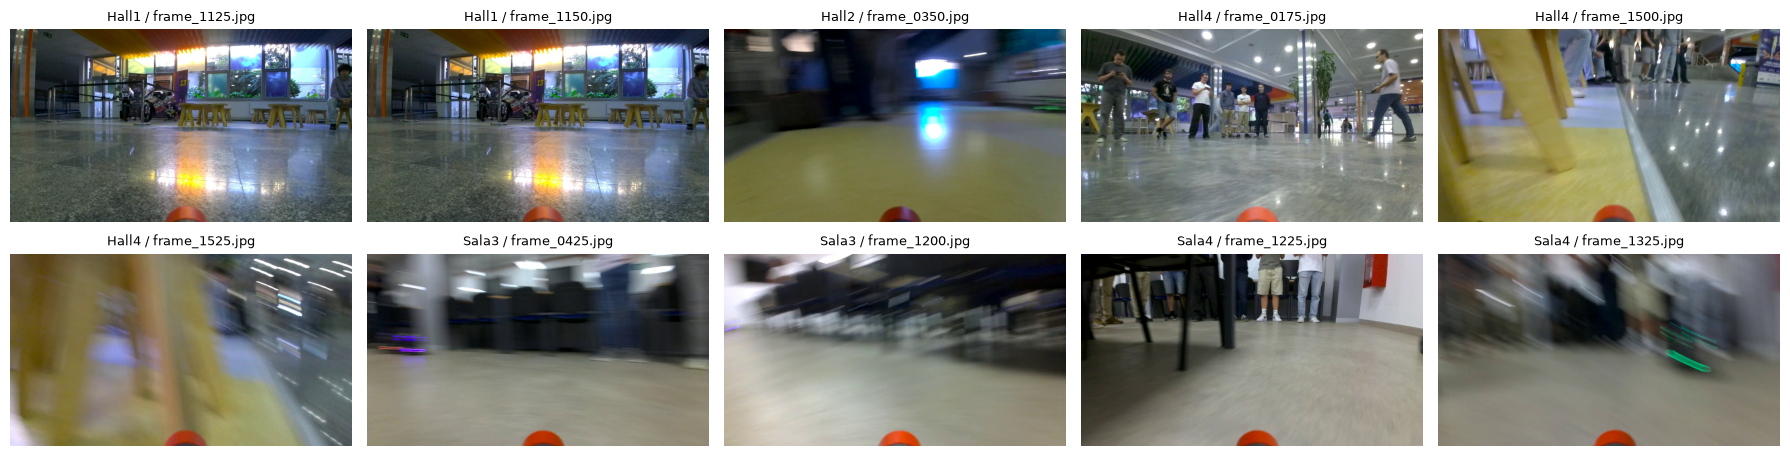

In [13]:
UNLABELLED = unlabelled_frames(PATH_DATA, DATA)
print(f'{len(UNLABELLED)} images without a label')
if UNLABELLED:
    show_gallery([(f'{seq.replace("RoboMaster-", "")} / {os.path.basename(p)}', p) for seq, p in UNLABELLED])

### Box width, height and aspect ratio

Each dot is a box. Wide boxes (aspect > 1) are robots seen from the side; narrow ones are robots seen from the front or partly hidden. Outliers far from the cloud are worth opening: they are often annotation mistakes.

In [14]:
def plot_box_shapes(boxes):
    """Scatter of normalised width vs height coloured by scenario, plus the aspect-ratio histogram."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
    for scen in SCENARIOS:
        b = boxes[boxes['scenario'] == scen]
        ax1.scatter(b['w_norm'], b['h_norm'], s=8, alpha=0.5, label=scen)
    ax1.set_xlabel('Width (fraction of image width)')
    ax1.set_ylabel('Height (fraction of image height)')
    ax1.set_title('Box shape')
    ax1.legend(title='Scenario')

    ax2.hist(boxes['aspect'], bins=np.logspace(np.log10(0.25), np.log10(4), 40), color='tab:blue')
    ax2.set_xscale('log')
    ax2.set_xticks([0.25, 0.5, 1, 2, 4], labels=['0.25', '0.5', '1', '2', '4'])
    ax2.set_xlabel('Aspect ratio (width / height)')
    ax2.set_ylabel('Boxes')
    ax2.set_title('Aspect ratio')
    plt.tight_layout()
    plt.show()

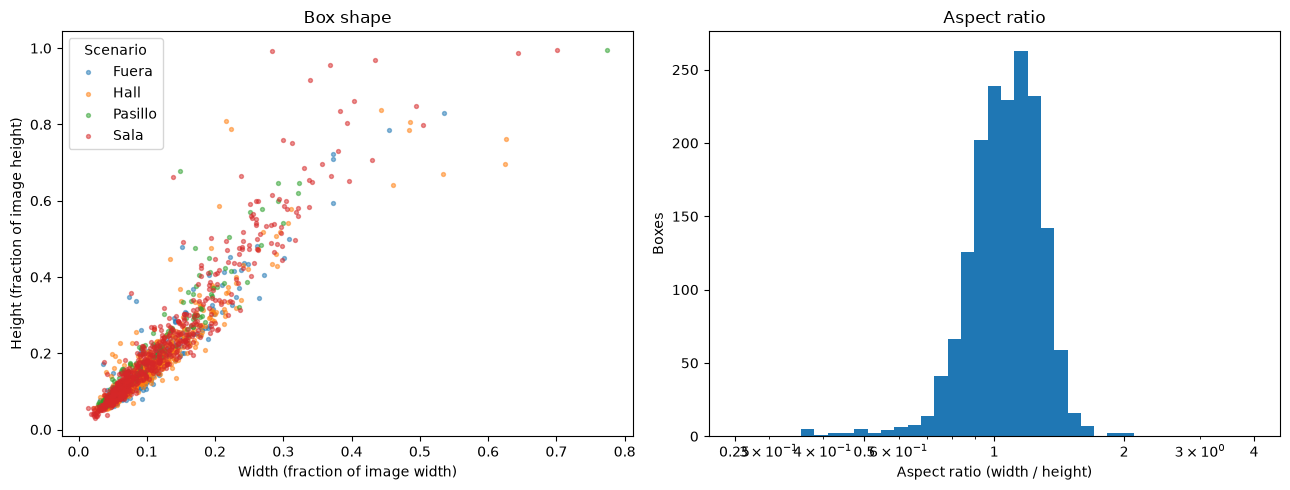

In [15]:
plot_box_shapes(BOXES)

### Object size vs. anchors

The torchvision detectors used in week 2 look for objects with a fixed set of **anchors**: by default sizes of 32, 64, 128, 256 and 512 px (FPN models) and aspect ratios 0.5, 1 and 2. If many boxes fall outside that range, the model will struggle with them.

We also split the boxes into the COCO size groups: **small** (< 32² px), **medium** (32²–96² px) and **large** (> 96² px). Small objects are the hardest to detect; if there are many, a higher input resolution helps.

> Note: the models resize the images before the anchors are applied (e.g. Faster R-CNN scales the short side to 800 px), so these sizes are approximate.

In [16]:
ANCHOR_SIZES = [32, 64, 128, 256, 512]   # torchvision FPN defaults
COCO_LIMITS = [0, 32 ** 2, 96 ** 2, np.inf]


def size_groups(boxes):
    """Share of small / medium / large boxes (COCO definition), per scenario and overall."""
    groups = pd.cut(boxes['area'], COCO_LIMITS, labels=['small', 'medium', 'large'], right=False)
    table = pd.crosstab(boxes['scenario'], groups, normalize='index')
    table.loc['ALL'] = groups.value_counts(normalize=True)
    return (100 * table).round(1).astype(str) + ' %'


def plot_box_sizes(boxes):
    """Histogram of the box size (square root of the area) with the default anchor sizes on top."""
    plt.figure(figsize=(9, 4))
    plt.hist(np.sqrt(boxes['area']), bins=np.logspace(np.log10(8), np.log10(1024), 50), color='tab:blue')
    for size in ANCHOR_SIZES:
        plt.axvline(size, color='tab:red', linestyle='--', linewidth=1)
    plt.xscale('log')
    plt.xticks(ANCHOR_SIZES, labels=ANCHOR_SIZES)
    plt.xlabel('Box size  $\\sqrt{w \\cdot h}$  (px, dashed = anchor sizes)')
    plt.ylabel('Boxes')
    plt.title('Box size vs. default anchors')
    plt.tight_layout()
    plt.show()

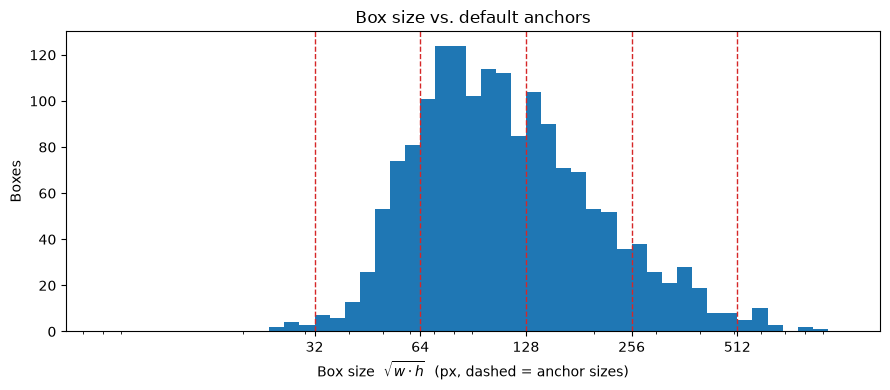

area,small,medium,large
scenario,,,
Fuera,0.0 %,47.7 %,52.3 %
Hall,0.0 %,48.3 %,51.7 %
Pasillo,0.0 %,36.7 %,63.3 %
Sala,1.4 %,37.9 %,60.6 %
ALL,0.5 %,43.3 %,56.1 %


In [17]:
plot_box_sizes(BOXES)
size_groups(BOXES)

### Box size per sequence

The same sizes, now split by sequence. A sequence whose robots are much bigger or smaller than the rest (e.g. recorded closer to them) is not representative of the others.

In [18]:
def plot_box_size_per_sequence(boxes):
    """Box plot of the box size (square root of the area) per sequence, with the anchor sizes as reference."""
    seqs = sorted(boxes['sequence'].unique())
    plt.figure(figsize=(max(6, 0.8 * len(seqs)), 4))
    plt.boxplot([np.sqrt(boxes.loc[boxes['sequence'] == s, 'area']) for s in seqs])
    for size in ANCHOR_SIZES:
        plt.axhline(size, color='tab:red', linestyle='--', linewidth=1)
    plt.yscale('log')
    plt.yticks(ANCHOR_SIZES, labels=ANCHOR_SIZES)
    plt.xticks(range(1, len(seqs) + 1), [s.replace('RoboMaster-', '') for s in seqs], rotation=45, ha='right')
    plt.ylabel('Box size  $\\sqrt{w \\cdot h}$  (px)')
    plt.title('Box size per sequence (dashed = anchor sizes)')
    plt.tight_layout()
    plt.show()

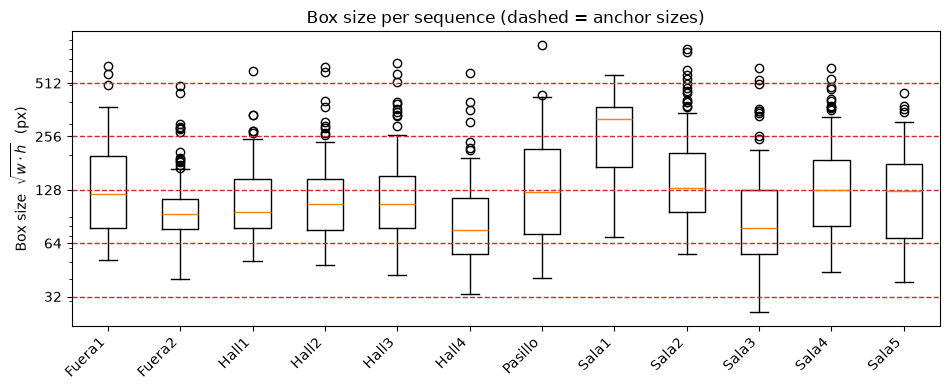

In [19]:
plot_box_size_per_sequence(BOXES)

### Where are the robots?

Heatmap of the box centres. Since the camera is mounted on a robot, the others usually appear around the horizon line, in the same band of the image. Random crops or vertical shifts in data augmentation should not push them where they never appear.

In [20]:
def plot_center_heatmap(boxes, bins=24):
    """2D histogram of the normalised box centres, overall and per scenario."""
    groups = [('All', boxes)] + [(s, boxes[boxes['scenario'] == s]) for s in SCENARIOS]
    fig, axes = subplot_grid(len(groups), sharey=False)
    fig.suptitle('Box centres')
    for ax, (name, b) in zip(axes, groups):
        ax.hist2d(b['cx_norm'], b['cy_norm'], bins=bins, range=[[0, 1], [0, 1]], cmap='viridis')
        ax.set_xlim(0, 1)
        ax.set_ylim(1, 0)          # image coordinates: y grows downwards
        ax.set_aspect(9 / 16)      # same proportions as a 16:9 frame
        ax.set_title(f'{name} ({len(b)} boxes)')
    plt.tight_layout()
    plt.show()

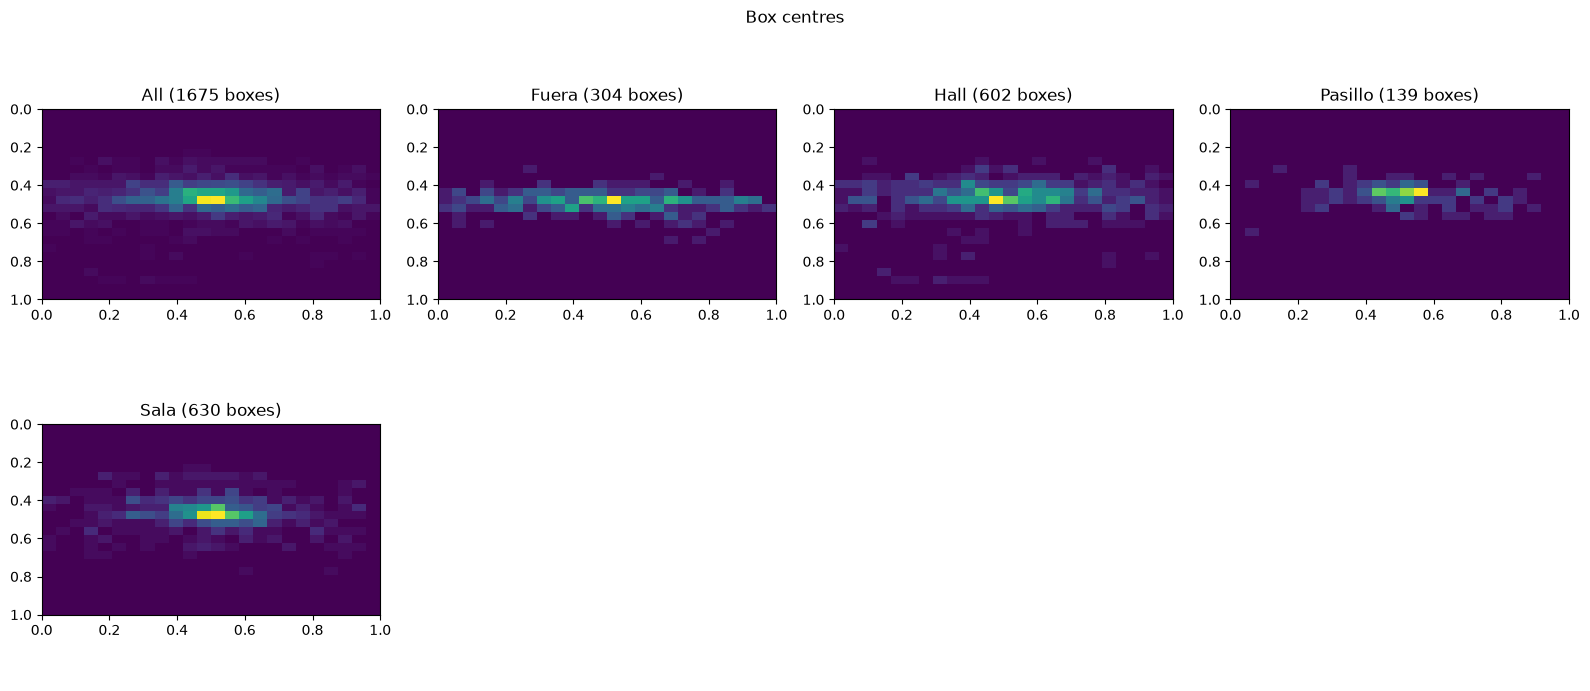

In [21]:
plot_center_heatmap(BOXES)

### Overlapping robots

Two boxes that overlap mean one robot is (partly) hiding another. We measure it with the **IoU** (intersection over union) of every pair of boxes in the same frame. Heavy overlap is hard for the detector: the non-maximum suppression step may merge both robots into one.

In [22]:
def iou(a, b):
    """Intersection over union of two [x_min, y_min, x_max, y_max] boxes."""
    iw = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    ih = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = iw * ih
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union else 0


def overlap_table(data):
    """Per sequence: frames with 2+ robots, overlapping pairs (IoU > 0) and heavily overlapping pairs (IoU > 0.5)."""
    rows = []
    for seq, frames in data.items():
        ious = [iou(a, b) for f in frames.values() for a, b in itertools.combinations(f['bboxes'], 2)]
        rows.append({'sequence': seq,
                     'frames with 2+ robots': sum(len(f['bboxes']) > 1 for f in frames.values()),
                     'box pairs': len(ious),
                     'pairs IoU > 0': sum(i > 0 for i in ious),
                     'pairs IoU > 0.5': sum(i > 0.5 for i in ious)})
    return pd.DataFrame(rows).set_index('sequence')

In [23]:
overlap_table(DATA)

,frames with 2+ robots,box pairs,pairs IoU > 0,pairs IoU > 0.5
sequence,,,,
RoboMaster-Fuera1,49,77,4,0
RoboMaster-Fuera2,65,151,8,0
RoboMaster-Hall1,35,57,3,0
RoboMaster-Hall2,49,85,13,0
RoboMaster-Hall3,73,153,21,0
RoboMaster-Hall4,57,107,7,0
RoboMaster-Pasillo,45,89,26,0
RoboMaster-Sala1,0,0,0,0
RoboMaster-Sala2,56,108,24,0


---
## Image statistics

Now we look at the frames themselves rather than the labels: resolution, lighting and sharpness. Big differences between scenarios mean the model has to cope with a **domain shift**; data augmentation can help to cover the gap.

### Resolution and orientation

All frames should have the same size, and it should match the `<size>` written in the `.xml` (if not, the boxes may be in the wrong place). A portrait sequence (e.g. a phone video recorded vertically) would show up here.

In [24]:
def check_resolution(data):
    """Print the image sizes found on disk and warn about frames whose .xml declares a different size."""
    real = {(seq, name): Image.open(f['frame_path']).size for seq, frames in data.items() for name, f in frames.items()}
    sizes = sorted(set(real.values()))
    print('Resolutions found:', ', '.join(f'{w}x{h} ({"landscape" if w >= h else "portrait"})' for w, h in sizes))
    mismatch = [key for key, size in real.items() if size != data[key[0]][key[1]]['size']]
    if mismatch:
        print(f'WARNING: {len(mismatch)} frames whose .xml size differs from the image, e.g. {mismatch[:5]}')
    else:
        print('Every .xml declares the real image size.')

In [25]:
check_resolution(DATA)

Resolutions found: 1280x720 (landscape)
Every .xml declares the real image size.


### Brightness, contrast and sharpness

For every frame we compute, on its grayscale version:
- **Brightness**: mean pixel value (0 = black, 255 = white).
- **Contrast**: standard deviation of the pixel values. Low contrast means a dull or washed-out image.
- **Sharpness**: variance of the Laplacian (an edge detector). Blurry frames (motion blur from the moving camera, out of focus) have few edges, so a low value. It only makes sense to compare it between frames of the same resolution.

These values are cached in `IMAGE_STATS` because reading every frame takes a while.

In [26]:
def image_stats(data, max_side=640):
    """Brightness, contrast and sharpness of every frame (downscaled so all frames are measured alike)."""
    rows = []
    for seq, frames in data.items():
        for frame_name, f in tqdm(frames.items(), desc=seq):
            img = Image.open(f['frame_path']).convert('L')
            img.thumbnail((max_side, max_side))
            gray = np.asarray(img, dtype=np.float32)
            rows.append({'sequence': seq, 'scenario': scenario(seq), 'frame': frame_name,
                         'brightness': float(gray.mean()), 'contrast': float(gray.std()),
                         'sharpness': float(ndimage.laplace(gray).var())})
    return pd.DataFrame(rows)


IMAGE_STATS = image_stats(DATA)

RoboMaster-Sala5: 100%|██████████| 74/74 [00:01<00:00, 61.58it/s]


In [27]:
def plot_image_stats(stats, by='sequence'):
    """One box plot per metric, grouped by sequence or by scenario."""
    metrics = ['brightness', 'contrast', 'sharpness']
    groups = sorted(stats[by].unique())
    fig, axes = plt.subplots(1, len(metrics), figsize=(5 * len(metrics), 4.5))
    fig.suptitle(f'Image statistics per {by}')
    for ax, metric in zip(axes, metrics):
        ax.boxplot([stats.loc[stats[by] == g, metric] for g in groups])
        ax.set_xticks(range(1, len(groups) + 1), labels=[g.replace('RoboMaster-', '') for g in groups],
                      rotation=45, ha='right')
        ax.set_title(metric)
    axes[2].set_yscale('log')   # sharpness spans several orders of magnitude
    plt.tight_layout()
    plt.show()

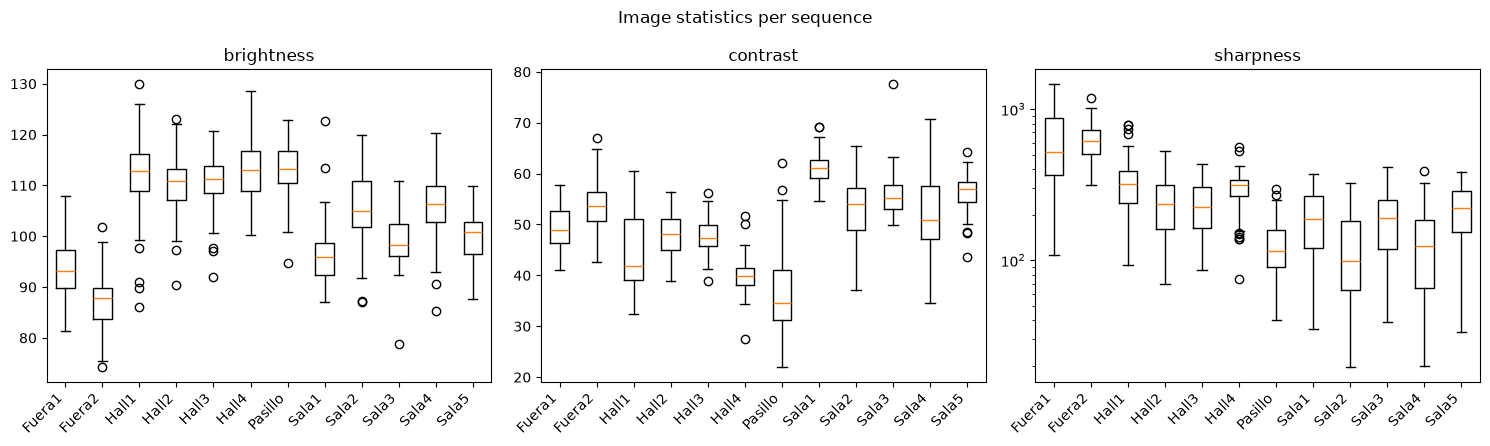

In [28]:
plot_image_stats(IMAGE_STATS)

### Blurriest and darkest frames

Numbers are easier to trust after looking at the images behind them. These are the frames at the extremes; if they are still usable, the dataset is in good shape. If not, consider removing them or adding blur / brightness augmentations so the model learns to handle them.

In [29]:
def show_extremes(stats, metric, n=4, lowest=True):
    """Show the n frames with the lowest (or highest) value of a metric, with their boxes."""
    rows = stats.sort_values(metric, ascending=lowest).head(n)
    fig, axes = plt.subplots(1, n, figsize=(4.5 * n, 3))
    fig.suptitle(f'{"Lowest" if lowest else "Highest"} {metric}')
    for ax, (_, r) in zip(axes, rows.iterrows()):
        f = DATA[r['sequence']][r['frame']]
        ax.imshow(plt.imread(f['frame_path']))
        for x_min, y_min, x_max, y_max in f['bboxes']:
            ax.add_patch(Rectangle((x_min, y_min), x_max - x_min, y_max - y_min,
                                   linewidth=2, edgecolor='tab:green', facecolor='none'))
        ax.set_title(f'{r["sequence"].replace("RoboMaster-", "")} / {r["frame"]}\n{metric} = {r[metric]:.1f}',
                     fontsize=9)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

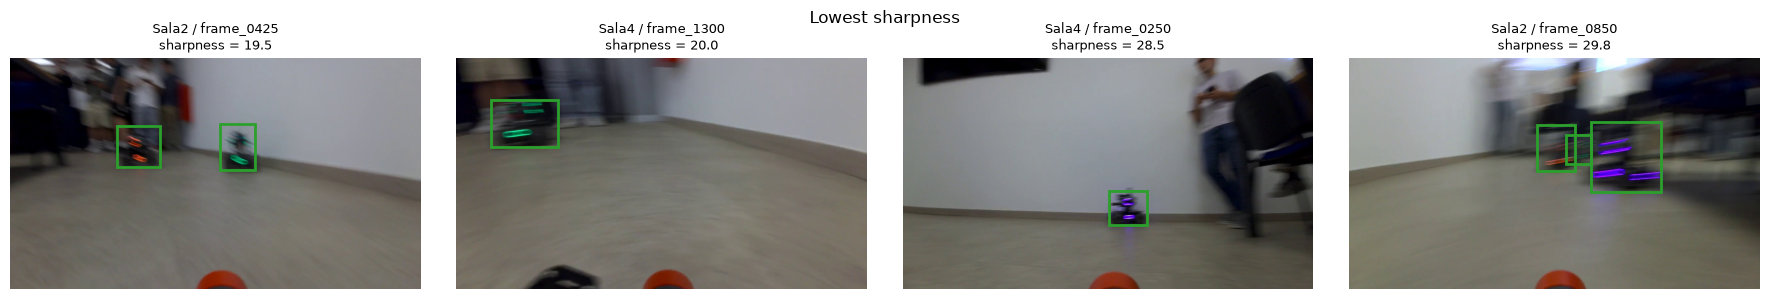

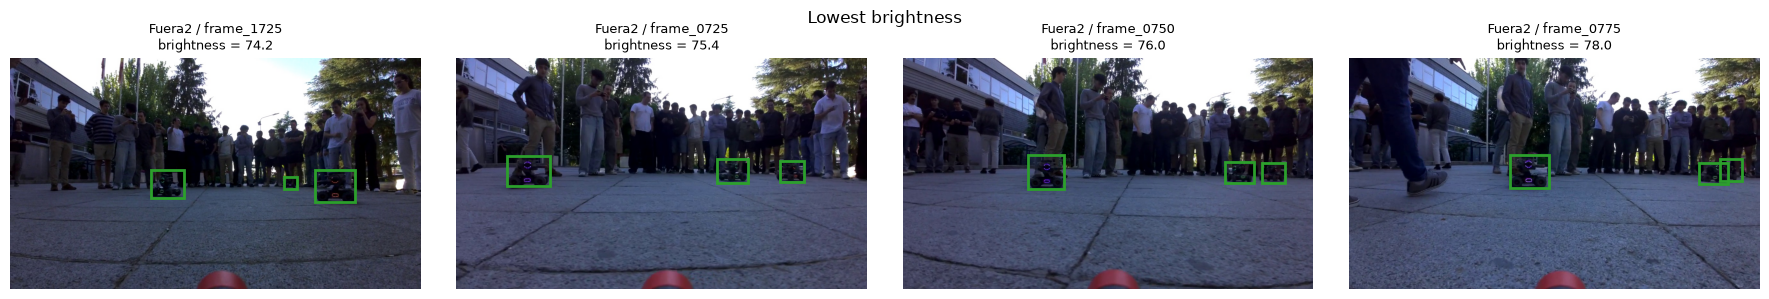

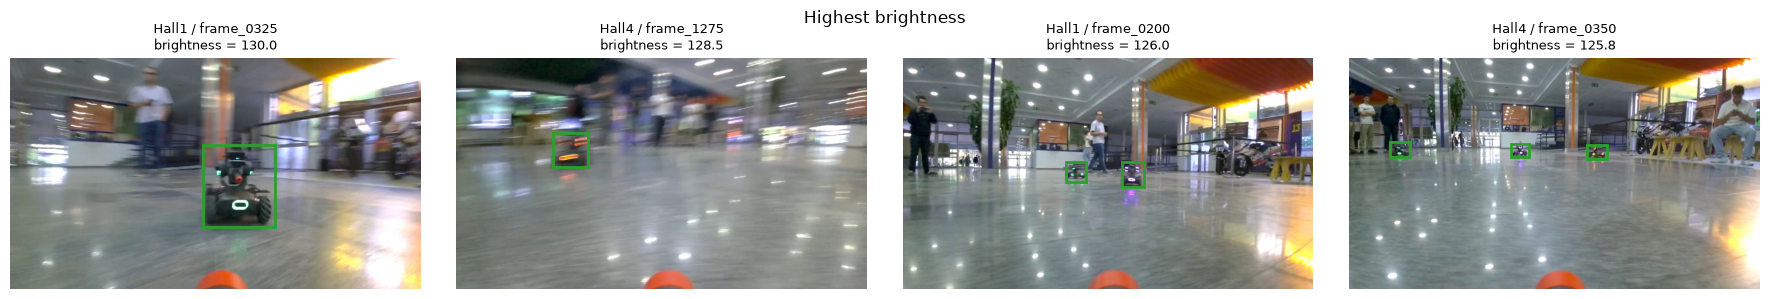

In [30]:
show_extremes(IMAGE_STATS, 'sharpness')
show_extremes(IMAGE_STATS, 'brightness')
show_extremes(IMAGE_STATS, 'brightness', lowest=False)

### Indoor vs. outdoor

Per-scenario summary of the image statistics. A scenario that stands apart (e.g. `Fuera`, outdoors) is a different domain: if it ends up only in training or only in validation, the validation score will be misleading.

In [31]:
IMAGE_STATS.groupby('scenario')[['brightness', 'contrast', 'sharpness']].agg(['mean', 'std']).round(1)

brightness      contrast      sharpness       
               mean  std     mean  std      mean    std
scenario                                               
Fuera          90.3  6.7     51.5  4.9     635.6  282.0
Hall          111.4  6.4     45.2  5.6     276.4  116.4
Pasillo       112.7  5.7     36.8  8.0     126.0   53.4
Sala          101.9  7.0     55.1  6.1     172.8   91.2

---
## Redundancy between frames

### How similar are consecutive frames?

Frames extracted from the same video are strongly related: same place, same lighting, same robots. We compare each frame with the previous one (mean absolute difference of the downscaled grayscale images, 0 = identical). Values close to 0 mean that the frame is almost a copy of the previous one and adds little new information.

In [32]:
def consecutive_differences(data, side=64):
    """Mean absolute difference (0-255) between each frame and the previous one, per sequence."""
    diffs = {}
    for seq, frames in data.items():
        imgs = [np.asarray(Image.open(f['frame_path']).convert('L').resize((side, side)), dtype=np.float32)
                for f in tqdm(frames.values(), desc=seq)]
        diffs[seq] = [np.abs(a - b).mean() for a, b in zip(imgs[:-1], imgs[1:])]
    return diffs


def plot_consecutive_differences(diffs):
    """Box plot of the consecutive-frame differences per sequence."""
    plt.figure(figsize=(max(6, 0.8 * len(diffs)), 4))
    plt.boxplot(list(diffs.values()))
    plt.xticks(range(1, len(diffs) + 1), [s.replace('RoboMaster-', '') for s in diffs], rotation=45, ha='right')
    plt.ylabel('Mean abs. difference (0-255)')
    plt.title('Difference between consecutive frames')
    plt.tight_layout()
    plt.show()

RoboMaster-Sala5: 100%|██████████| 74/74 [00:00<00:00, 85.15it/s]


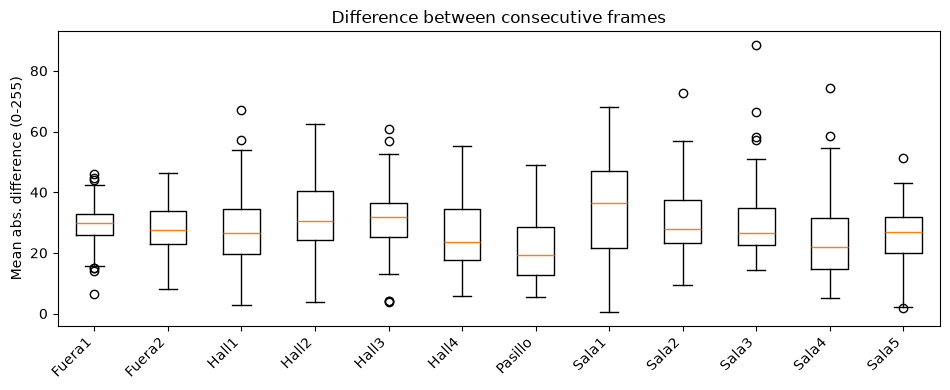

In [33]:
DIFFS = consecutive_differences(DATA)
plot_consecutive_differences(DIFFS)

---
## Summary table

Everything above in one table, one row per sequence.

In [34]:
def summary_table(data, boxes, stats, diffs):
    """One row per sequence with the key numbers of the EDA."""
    rows = []
    for seq, frames in data.items():
        b = boxes[boxes['sequence'] == seq]
        s = stats[stats['sequence'] == seq]
        n_boxes = [len(f['bboxes']) for f in frames.values()]
        n_images = len(list_dir(os.path.join(PATH_DATA, seq, 'images')))
        rows.append({'sequence': seq, 'scenario': scenario(seq),
                     'frames': len(frames), 'images w/o label': n_images - len(frames),
                     'boxes': len(b), 'robots / frame': np.mean(n_boxes),
                     '% empty frames': 100 * np.mean(np.array(n_boxes) == 0),
                     'median box size (px)': np.sqrt(b['area']).median(),
                     '% small boxes': 100 * (b['area'] < 32 ** 2).mean(),
                     'brightness': s['brightness'].mean(),
                     'sharpness': s['sharpness'].median(),
                     'consecutive diff': np.median(diffs[seq])})
    return pd.DataFrame(rows).set_index('sequence').round(1)


SUMMARY = summary_table(DATA, BOXES, IMAGE_STATS, DIFFS)
SUMMARY

,scenario,frames,images w/o label,boxes,robots / frame,% empty frames,median box size (px),% small boxes,brightness,sharpness,consecutive diff
sequence,,,,,,,,,,,
RoboMaster-Fuera1,Fuera,64,0,127,2.0,0.0,121.0,0.0,93.7,516.9,29.799999
RoboMaster-Fuera2,Fuera,69,0,177,2.6,0.0,94.0,0.0,87.2,611.5,27.500000
RoboMaster-Hall1,Hall,66,2,112,1.7,0.0,95.3,0.0,111.3,317.4,26.500000
RoboMaster-Hall2,Hall,66,1,133,2.0,0.0,107.1,0.0,110.2,235.2,30.500000
RoboMaster-Hall3,Hall,89,0,202,2.3,0.0,107.0,0.0,110.6,224.0,31.700001
RoboMaster-Hall4,Hall,73,3,155,2.1,0.0,76.1,0.0,113.5,314.1,23.500000
RoboMaster-Pasillo,Pasillo,72,0,139,1.9,0.0,124.5,0.0,112.7,115.2,19.400000
RoboMaster-Sala1,Sala,40,0,40,1.0,0.0,321.9,0.0,96.8,186.3,36.500000
RoboMaster-Sala2,Sala,68,0,150,2.2,0.0,130.7,0.0,105.6,98.8,27.900000
